# Shears — figures

The figures of Supplementary Note 3, made **only from saved files**
(`data/disharmonic_fold.npz` from `s03a`,
`results/shears.npz` from `s03b`, `results/shears_ensemble.npz` from `s03c`):
numpy and matplotlib. Writes `figS_shears_rk4`, `figS_shears_rays`, `figS_shears_sweep` and `figS_shears_convergence`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import diagnostics
figstyle.apply()

DATA = Path("./data/disharmonic_fold.npz")       # the fitted section
RES = Path("./results/shears.npz")
FIG_DIR = Path("./figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

d, r = np.load(DATA), np.load(RES)
ens = np.load(RES.parent / "shears_ensemble.npz")     # the loss across bases, from s03c
AX = d["ax"]
HALF = float(AX[-1])
SCHEME_COLOR = {"lie": figstyle.HORIZON_PALETTE[4], "strang": figstyle.HORIZON_PALETTE[0],
                "yoshida": figstyle.HORIZON_PALETTE[2], "rk4": "0.15"}
SCHEME_LABEL = {"lie": "Lie–Trotter", "strang": "Strang",
                "yoshida": "Yoshida", "rk4": "RK4"}


def tint(color, f):
    # Opaque mix of `color` with white, f in [0, 1].
    from matplotlib.colors import to_rgb
    return tuple(1.0 - f * (1.0 - np.asarray(to_rgb(color))))


def square_axes(fig, x0, y0, w, fig_w, fig_h):
    return fig.add_axes([x0 / fig_w, y0 / fig_h, w / fig_w, w / fig_h])


def frame(ax, *, xlabel=True, ylabel=False):
    ax.set_xlim(-HALF, HALF)
    ax.set_ylim(-HALF, HALF)
    ax.set_aspect("equal")
    ax.set_xticks([-500, 0, 500])
    ax.set_yticks([-500, 0, 500])
    ax.set_xlabel("x (m)" if xlabel else "")
    ax.set_ylabel("z (m)" if ylabel else "")
    if not xlabel:
        ax.set_xticklabels([])
    if not ylabel:
        ax.set_yticklabels([])


def unit_colours(levels):
    return figstyle.litho_cmap(np.arange(len(levels) + 1))       # the lithology colours of the main figures


def true_horizons(ax):
    # The drawn horizons of the section, dashed, as in the main-text figures.
    for k in range(int(d["n_lines"])):
        ax.plot(*d[f"line_{k}"].T, color="0.1", lw=0.7, ls=(0, (3, 2)), zorder=4)


def draw_units(ax, elev, levels):
    units = np.digitize(elev, np.sort(levels))
    cmap, norm = unit_colours(levels)
    ax.pcolormesh(AX, AX, units.T, cmap=cmap, norm=norm, shading="auto", rasterized=True)
    ax.contour(AX, AX, elev.T, levels=sorted(levels), colors="white", linewidths=0.6, linestyles="solid")

## Fig. S5: the data, the RK4 fit, its velocity and its flow

**a** The drawn horizons (dashed), the sampled contacts and the bedding. **b** The RK4 fit, over the
drawn horizons. **c** Its velocity. **d** The trajectories along which its flow carries a grid of
present-day points (dots) back to the reference, over the fitted horizons.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


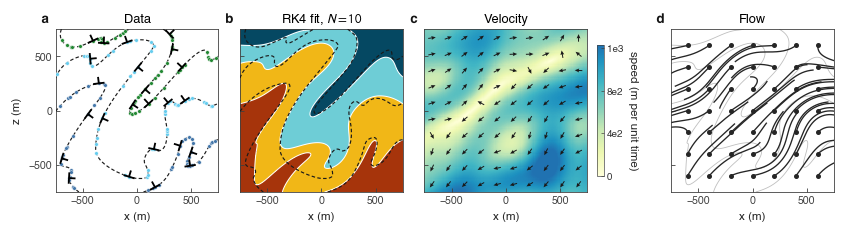

In [7]:
from matplotlib.colors import LinearSegmentedColormap

# Speed as colour, stopping at mid blue so that the dark arrows read everywhere.
cmap = LinearSegmentedColormap.from_list("speed", plt.get_cmap("YlGnBu")(np.linspace(0.0, 0.7, 256)))


def draw_field(ax, axis, field, vmax, cmap, every=15, length=70.0):
    # Speed as colour; arrows of one length (m) give only the direction. Arrows are left out where the
    # speed is under 2% of vmax, as their direction means little there.
    n = len(axis)
    speed = np.linalg.norm(field, axis=1).reshape(n, n)
    m = ax.pcolormesh(axis, axis, speed.T, cmap=cmap, vmin=0, vmax=vmax, shading="auto", rasterized=True)
    q = slice(every // 2, None, every)             # off the edges, so no arrow is cut
    F = field.reshape(n, n, 2)[q, q]
    S = speed[q, q]
    X, Z = np.meshgrid(axis, axis, indexing="ij")
    keep = S > 0.02 * vmax
    U = np.where(keep, F[..., 0] / np.maximum(S, 1e-12), np.nan)
    W = np.where(keep, F[..., 1] / np.maximum(S, 1e-12), np.nan)
    ax.quiver(X[q, q], Z[q, q], U, W, color="0.1", angles="xy", scale_units="xy", scale=1.0 / length,
              width=0.006, headwidth=4.0, headlength=4.5, headaxislength=4.0, pivot="mid")
    return m


def one_row(n, *, gap=0.10, bottom=0.42, top=0.26, right=0.10):
    # n square panels across the print width; only the first carries the z axis.
    # gap: one width for every gap, or a list of the n - 1 gaps.
    left = 0.50
    gaps = list(gap) if np.iterable(gap) else [gap] * (n - 1)
    w = (figstyle.PRINT_WIDTH - left - right - sum(gaps)) / n
    fig_h = top + w + bottom
    fig = figstyle.print_figure(height=fig_h)
    x0 = left + np.r_[0.0, np.cumsum([w + g for g in gaps])]
    axes = [square_axes(fig, x, bottom, w, figstyle.PRINT_WIDTH, fig_h) for x in x0]
    return fig, axes, fig_h


def cbar_beside(fig, ax, mappable, label):
    # A vertical colour bar just right of one panel, in the gap after it.
    p = ax.get_position()
    cax = fig.add_axes([p.x1 + 0.012, p.y0 + 0.1 * p.height, 0.008, 0.8 * p.height])
    figstyle.add_cbar(cax, mappable, label)


def cbar_under(fig, fig_h, axes, mappable, label):
    p0, p1 = axes[0].get_position(), axes[-1].get_position()
    width = p1.x1 - p0.x0
    cax = fig.add_axes([p0.x0 + 0.12 * width, p0.y0 - 0.52 / fig_h, 0.76 * width, 0.05 / fig_h])
    figstyle.add_cbar(cax, mappable, label)


def draw_data(ax):
    # The drawn horizons (dashed), the sampled contacts (dots, one colour per horizon) and the bedding (ticks).
    true_horizons(ax)
    for h, c in zip(d["horizons"], figstyle.HORIZON_PALETTE):
        ax.scatter(*h.T, s=5, color=c, edgecolors="white", linewidths=0.3, zorder=5)
    figstyle.draw_younging(ax, d["gp"], d["gv"], color="k", quiver_scale=0.008)


def draw_loss(ax):
    # The loss of both maps against iteration across the bases of s03c (same bases and training), on a
    # right-hand log axis: the median, with the interquartile range shaded. The last entry of each curve is
    # the reloaded best state, not a training iteration, so it is left out of the plot.
    ax.set_aspect("auto")
    it = ens["iteration"][:-1]
    for name, label in (("sweep", "one sweep"), ("rk4", f"RK4, $N = {int(ens['n_rk4'])}$")):
        color = SCHEME_COLOR["lie" if name == "sweep" else "rk4"]
        lo, mid, hi = np.nanpercentile(ens[f"{name}_loss"][:, :-1], (25, 50, 75), axis=0)
        ax.fill_between(it, lo, hi, color=tint(color, 0.3), lw=0)
        ax.loglog(it, mid, lw=1.0, label=label, color=color)
    ax.set_xlabel("iteration")
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")
    ax.set_ylabel("loss", rotation=270, labelpad=10)
    ax.set_title("Fit to the data")


fig, axes, fig_h = one_row(4, gap=(0.18, 0.18, 0.70), bottom=0.42)   # wide gap: the colour bar of c
draw_data(axes[0])
axes[0].set_title("Data")
draw_units(axes[1], r["rk4_psi"], r["rk4_levels"])
true_horizons(axes[1])
axes[1].set_title(rf"RK4 fit, $N = {int(r['n_rk4'])}$")
vmax = float(np.quantile(np.linalg.norm(r["rk4_v_grid"], axis=1), 0.98))
m_v = draw_field(axes[2], r["ax_v"], r["rk4_v_grid"], vmax, cmap)
axes[2].set_title("Velocity")
paths = r["rk4_paths"]
axes[3].contour(AX, AX, r["rk4_psi"].T, levels=sorted(r["rk4_levels"]), colors="0.75", linewidths=0.5,
                linestyles="solid")
for p in range(paths.shape[1]):
    axes[3].plot(paths[:, p, 0], paths[:, p, 1], color="0.15", lw=0.8)
    axes[3].plot(*paths[0, p], "o", color="0.15", ms=2.0)
axes[3].set_title("Flow")
for i, ax in enumerate(axes):
    frame(ax, ylabel=i == 0)
cbar_beside(fig, axes[2], m_v, "speed (m per unit time)")
for ax, letter in zip(axes, "abcd"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "figS_shears_rk4")
plt.show()


## Fig. S6: the RK4 fit's velocity, shear by shear

**a** The velocity of the RK4 fit (Fig. S5c). **b–e** Its four strongest shears, numbered by their
place in the sweep, on one colour scale of their own. They add up, with the other shears, to **a**.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


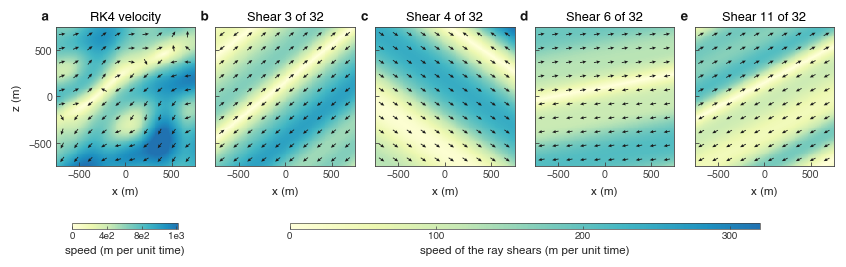

In [8]:
fig, axes, fig_h = one_row(5, gap=0.17, bottom=0.95)
vmax = float(np.quantile(np.linalg.norm(r["v_grid"], axis=1), 0.98))
m_v = draw_field(axes[0], r["ax_rays"], r["v_grid"], vmax, cmap)
axes[0].set_title("RK4 velocity")
vmax_r = float(np.linalg.norm(r["rays"], axis=2).max())
n_rays = len(r["ray_rms"])
for j, k in enumerate(r["ray_index"]):
    m_r = draw_field(axes[1 + j], r["ax_rays"], r["rays"][j], vmax_r, cmap)
    axes[1 + j].set_title(f"Shear {int(k)} of {n_rays}")
for i, ax in enumerate(axes):
    frame(ax, ylabel=i == 0)
cbar_under(fig, fig_h, axes[:1], m_v, "speed (m per unit time)")
cbar_under(fig, fig_h, axes[1:], m_r, "speed of the ray shears (m per unit time)")
for ax, letter in zip(axes, "abcde"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "figS_shears_rays")
plt.show()

## Fig. S8: the fitted map, shear by shear

The 32 shears of the sweep fit, each applied once, in order. **a** Reference layers. **b–e** The
layers after the first 4, 8, 16 and all 32 shears; **e** adds the drawn horizons (dashed). Below
**b–e**, a cumulative rose of the shears applied so far: each shear's RMS displacement over the
section, placed in the 15° sector of its direction and the opposite one, coloured by the group of
shears each panel adds. **f** The loss of one sweep and of RK4 against iteration across the bases of `s03c`: median and
interquartile range.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


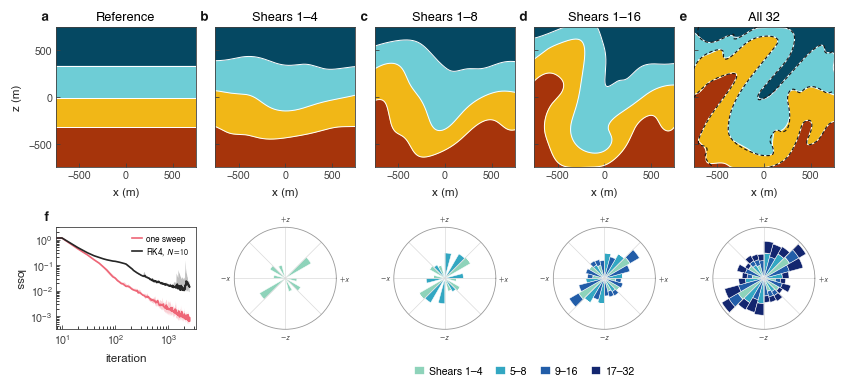

In [9]:
STAGES = (0, 4, 8, 16)                       # shears applied in panels a-d; e has them all
states, zb = r["layer_states"], r["z_bounds"]
fit_levels = np.sort(r["sweep_levels"])
UNIT_CMAP, UNIT_NORM = unit_colours(fit_levels)
STAGES = STAGES + (states.shape[0] - 1,)


def fill_layers(ax, lines):
    # Fill the strip between each pair of boundaries with the colour of its unit.
    for i in range(len(zb) - 1):
        unit_id = np.digitize(0.5 * (zb[i] + zb[i + 1]), fit_levels)
        poly = np.vstack([lines[i], lines[i + 1][::-1]])
        colour = UNIT_CMAP(UNIT_NORM(unit_id))
        ax.fill(poly[:, 0], poly[:, 1], facecolor=colour, edgecolor=colour, lw=0.4, rasterized=True)   # edge hides seams
    for lv in fit_levels:                        # the horizons, as in Fig. S5
        line = lines[int(np.argmin(np.abs(zb - lv)))]
        ax.plot(line[:, 0], line[:, 1], color="white", lw=0.6)


def shear_motion(k):
    # Shear k: the direction it moves material in (the principal axis of its displacements) and how much
    # it moves the rock in view (its RMS displacement over the section, from s03b).
    disp = (states[k] - states[k - 1]).reshape(-1, 2)
    direction = np.linalg.svd(disp - disp.mean(0), full_matrices=False)[2][0]
    return direction, float(r["shear_rms"][k - 1])


motion = [None] + [shear_motion(k) for k in range(1, states.shape[0])]
largest = max(m for _, m in motion[1:])


ROSE_BIN = 15.0                                   # sector width (degrees)
edges = np.radians(np.arange(0.0, 180.0 + ROSE_BIN, ROSE_BIN))


def rose_totals(first, last):
    # Total RMS displacement of the shears in each sector of motion direction (axial, 0-180 deg).
    theta = np.array([np.arctan2(motion[k][0][1], motion[k][0][0]) % np.pi for k in range(first, last + 1)])
    mag = np.array([motion[k][1] for k in range(first, last + 1)])
    return np.histogram(theta, bins=edges, weights=mag)[0]


def draw_rose(ax, n_groups, rmax):
    # Cumulative axial rose of the first n_groups groups of shears, stacked by group; each sector is drawn
    # twice, opposite ways, and a group's ring runs between the square roots of the totals before and
    # after it, so every coloured area is proportional to that group's displacement.
    width = np.radians(ROSE_BIN)
    below = np.zeros(len(edges) - 1)
    for j in range(n_groups):
        total = below + rose_totals(*GROUPS[j])
        for offset in (0.0, np.pi):
            ax.bar(edges[:-1] + 0.5 * width + offset, np.sqrt(total) - np.sqrt(below), bottom=np.sqrt(below),
                   width=width, color=GROUP_COLORS[j], edgecolor="white", linewidth=0.3)
        below = total
    ax.set_ylim(0, rmax)
    ax.set_yticks([])
    ax.set_xticks(np.radians(np.arange(0, 360, 45)),
                  ["$+x$", "", "$+z$", "", "$-x$", "", "$-z$", ""])     # orientation, as in the sections
    ax.tick_params(axis="x", labelsize=figstyle.pt(6.5), pad=-2, colors="0.3")
    ax.grid(color="0.85", lw=0.4)
    ax.spines["polar"].set_color("0.6")
    ax.spines["polar"].set_linewidth(0.5)


fan_h, fan_gap = 0.85, 0.50                   # size of the fans and the space above them (in)
key_h = 0.45                                  # the key of the shear groups, below the fans (in)
fig, axes, fig_h = one_row(5, gap=0.16, bottom=key_h + fan_gap + fan_h + 0.22)
roses = []
GROUPS = [(STAGES[i - 1] + 1, STAGES[i]) for i in range(1, len(STAGES))]      # the shears each panel adds
GROUP_COLORS = plt.get_cmap("YlGnBu")(np.linspace(0.35, 0.95, len(GROUPS)))
rose_max = 1.05 * np.sqrt(sum(rose_totals(*g) for g in GROUPS).max())          # the full rose fills its circle
n_shears = states.shape[0] - 1
for i, (ax, k) in enumerate(zip(axes, STAGES)):
    ax.set_facecolor("0.86")
    fill_layers(ax, states[k])
    frame(ax, ylabel=i == 0)
    ax.set_title("Reference" if k == 0 else ("Shear 1" if k == 1 else
                 (f"All {n_shears}" if k == n_shears else f"Shears 1–{k}")))
    if k > 0:                                                    # the shears since the previous panel
        p = ax.get_position()
        fan = fig.add_axes([p.x0 + 0.5 * p.width - 0.5 * fan_h / figstyle.PRINT_WIDTH,
                            p.y0 - (fan_gap + fan_h) / fig_h, fan_h / figstyle.PRINT_WIDTH, fan_h / fig_h],
                           projection="polar")
        draw_rose(fan, i, rose_max)
        roses.append(fan)
true_horizons(axes[-1])

# f: the loss of both fits, in the space below panel a, level with the roses
pa, pr = axes[0].get_position(), roses[0].get_position()
loss_ax = fig.add_axes([pa.x0, pr.y0, pa.width, pr.height])
draw_loss(loss_ax)
loss_ax.yaxis.tick_left()
loss_ax.yaxis.set_label_position("left")
loss_ax.set_ylabel("loss")
loss_ax.set_title("")
from matplotlib.ticker import LogLocator
loss_ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=12))      # every decade labelled
loss_ax.legend(loc="upper right", frameon=False, handlelength=1.2, fontsize=figstyle.pt(7))

from matplotlib.patches import Patch
p_first, p_last = roses[0].get_position(), roses[-1].get_position()    # the key, centred below the fans
key = fig.legend(handles=[Patch(facecolor=c, edgecolor="white", label=("Shears " if j == 0 else "") + f"{a}–{b}")
                          for j, ((a, b), c) in enumerate(zip(GROUPS, GROUP_COLORS))],
                 loc="center", ncol=len(GROUPS), frameon=False,
                 handlelength=1.0, handleheight=1.0, handletextpad=0.4, columnspacing=1.2,
                 bbox_to_anchor=(0.5 * (p_first.x0 + p_last.x1), p_first.y0 - (0.12 + 0.5 * key_h) / fig_h))
for ax, letter in zip(axes + [loss_ax], "abcdef"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "figS_shears_sweep")
plt.show()

## Fig. S7: composing the RK4 fit's shears

Restoration paths of points on the drawn horizons (dots) built by composing the RK4 fit's shears,
every translation drawn, against the flow of its velocity (black). Grey lines are the RK4 fit's
horizons. **a–c** Lie–Trotter, `N` from `ORBITS` in s03b. **d, e** Strang. **f** The greatest distance
to the flow against `N`, for both compositions and for RK4.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


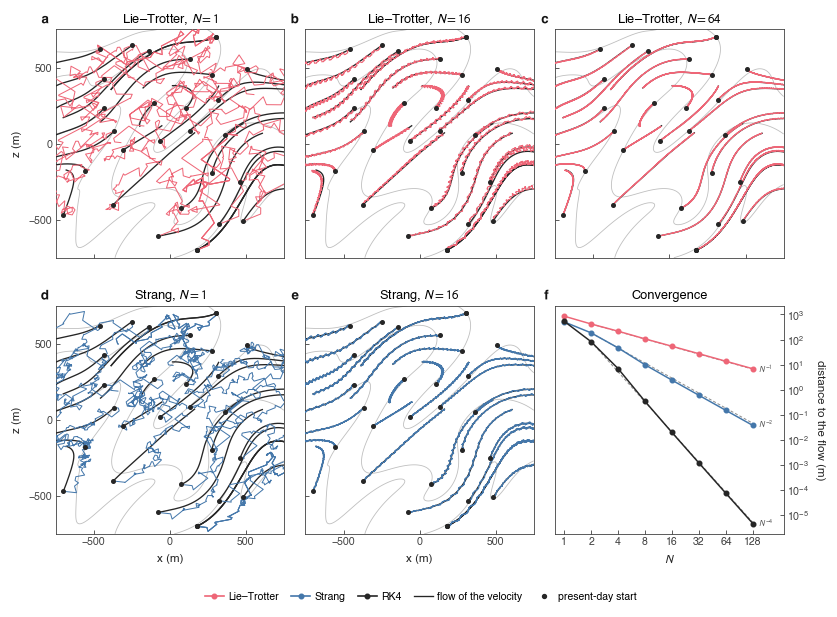

In [5]:
fig_w = figstyle.PRINT_WIDTH
left, right, gap, row_gap = 0.50, 0.52, 0.18, 0.40       # right: panel f's axis label
w = (fig_w - left - right - 2 * gap) / 3.0
top, bottom = 0.26, 0.58
fig_h = top + 2 * w + row_gap + bottom
fig = figstyle.print_figure(height=fig_h)
cols = [left + k * (w + gap) for k in range(3)]
rows = [bottom + w + row_gap, bottom]
axes = [square_axes(fig, cols[i % 3], rows[i // 3], w, fig_w, fig_h) for i in range(6)]

ORBIT_NAME = {"lie": "Lie–Trotter", "strang": "Strang"}
exact = r["exact_path"]
keys = [str(s) for s in r["orbit_keys"]]                 # Lie-Trotter N = 1, 2, 4; Strang N = 1, 2
for i, key in enumerate(keys):
    ax, o = axes[i], r[f"orbit_{key}"]
    scheme, n = key.rsplit("_", 1)
    ax.contour(AX, AX, r["rk4_psi"].T, levels=sorted(r["rk4_levels"]), colors="0.75", linewidths=0.5,
               linestyles="solid")
    for p in range(o.shape[1]):
        ax.plot(exact[:, p, 0], exact[:, p, 1], color="0.15", lw=0.8, zorder=3)
        ax.plot(o[:, p, 0], o[:, p, 1], color=SCHEME_COLOR[scheme], lw=0.6, zorder=4)   # every translation
        ax.plot(*o[0, p], "o", color="0.15", ms=2.0, zorder=5)
    frame(ax, xlabel=i >= 3, ylabel=i % 3 == 0)
    ax.set_title(f"{ORBIT_NAME[scheme]}, $N = {n}$")

ax = axes[5]
ax.set_aspect("auto")
for s in ("lie", "strang", "rk4"):
    ax.loglog(r[f"nvals_{s}"], r[f"error_{s}"], "o-", color=SCHEME_COLOR[s], ms=2.6, lw=0.9)
for order, s in ((1, "lie"), (2, "strang"), (4, "rk4")):
    n, e = r[f"nvals_{s}"].astype(float), r[f"error_{s}"]
    guide = e[1] * (n[1:] / n[1]) ** (-order)
    ax.loglog(n[1:], guide, ls=(0, (3, 2)), color="0.55", lw=0.6, zorder=1)
    ax.text(n[-1] * 1.15, guide[-1], rf"$N^{{-{order}}}$", va="center", ha="left", color="0.35",
            fontsize=figstyle.pt(7))
ax.set_xticks(r["nvals_lie"], [str(n) for n in r["nvals_lie"]])
ax.minorticks_off()
ax.set_xlim(0.8, r["nvals_lie"][-1] * 2.2)
ax.set_xlabel("$N$")
ax.yaxis.tick_right()                                    # clear of panel e
ax.yaxis.set_label_position("right")
ax.set_ylabel("distance to the flow (m)", rotation=270, labelpad=10)
ax.set_title("Convergence")

key = [Line2D([], [], color=SCHEME_COLOR[s], lw=1.0, marker="o", ms=2.6, label=SCHEME_LABEL[s])
       for s in ("lie", "strang", "rk4")] + \
      [Line2D([], [], color="0.15", lw=0.8, label="flow of the velocity"),
       Line2D([], [], ls="", marker="o", ms=2.2, color="0.15", label="present-day start")]
fig.legend(handles=key, loc="upper center", ncol=len(key), frameon=False, handlelength=1.8,
           columnspacing=1.2, handletextpad=0.4, bbox_to_anchor=(0.5, 0.17 / fig_h))
for ax, letter in zip(axes, "abcdef"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "figS_shears_convergence")
plt.show()


## Numbers quoted in Supplementary Note 3

In [6]:
for name in ("sweep", "rk4"):
    curve = r[name + "_loss_curve"]
    print(f"{name} fit: loss {float(r[name + '_loss']):.2g} (half way {curve[len(curve) // 2]:.2g}), "
          f"{float(r[name + '_seconds']):.0f} s, "
          f"max ||D phi_h - I|| {float(r[name + '_step']):.2f}")
print(f"band {r['band']}, RK4 N={int(r['n_rk4'])}; largest displacement of the flow {float(r['displacement']):.0f} m")
for s in ("lie", "strang", "rk4"):
    e = r[f"error_{s}"]
    print(f"{s:>8}: " + ", ".join(f"N={n}: {v:.3g} m" for n, v in zip(r[f'nvals_{s}'], e))
          + f"; ratios {np.round(e[:-1] / e[1:], 1).tolist()}")
print(f"max |det J - 1|: one-way sweep {float(r['det_sweep']):.1e}, RK4 N={int(r['n_rk4'])} {float(r['det_rk4']):.1e}")
for k in r["orbit_keys"]:
    print(f"{k}: {r[f'orbit_{k}'].shape[0] - 1} translations")
for name in ("sweep", "rk4"):
    final = ens[f"{name}_loss"][:, -1]
    print(f"{len(final)} bases, {name}: final loss median {np.nanmedian(final):.2g}, "
          f"interquartile range {np.nanpercentile(final, 25):.2g}-{np.nanpercentile(final, 75):.2g}")


sweep fit: loss 0.00033 (half way 0.0011), 19 s, max ||D phi_h - I|| 10.21
rk4 fit: loss 0.013 (half way 0.015), 92 s, max ||D phi_h - I|| 0.56
band [1000. 4000.], RK4 N=10; largest displacement of the flow 1204 m
     lie: N=1: 861 m, N=2: 419 m, N=4: 216 m, N=8: 106 m, N=16: 54.1 m, N=32: 27.2 m, N=64: 13.6 m, N=128: 6.81 m; ratios [2.1, 1.9, 2.0, 2.0, 2.0, 2.0, 2.0]
  strang: N=1: 510 m, N=2: 186 m, N=4: 46.7 m, N=8: 9.87 m, N=16: 2.4 m, N=32: 0.595 m, N=64: 0.149 m, N=128: 0.0371 m; ratios [2.7, 4.0, 4.7, 4.1, 4.0, 4.0, 4.0]
     rk4: N=1: 541 m, N=2: 82.6 m, N=4: 6.99 m, N=8: 0.342 m, N=16: 0.0196 m, N=32: 0.00118 m, N=64: 7.24e-05 m, N=128: 4.49e-06 m; ratios [6.5, 11.8, 20.4, 17.5, 16.6, 16.3, 16.1]
max |det J - 1|: one-way sweep 1.9e-14, RK4 N=10 5.1e-04
lie_1: 32 translations
lie_16: 512 translations
lie_64: 2048 translations
strang_1: 63 translations
strang_16: 993 translations
15 bases, sweep: final loss median 0.00062, interquartile range 0.00041-0.00086
15 bases, rk4: fina